# Problem Set 2: Two-Period Ramsey Taxation in a Small Open Economy (Q5–Q7)

Numerical part of the problem set. A household lives for two periods, values consumption and leisure through nested CES utility, and can save at the world interest rate R. A CES production frontier turns labor into the consumption good and a fixed government good G in each period. The government finances G with wage taxes τ_w,t, consumption taxes τ_t, and one-period debt B. Question 5 solves the Ramsey problem with wage taxes and debt only, Question 6 adds consumption taxes, and Question 7 varies the discount factor β to see when the extra instrument matters.

Parameters: R = 1.04, β = 1/1.04 (so βR = 1), θ = 2, η = 0.7, ψ = 1.5, G = 0.15, ωᶜ = 0.6, ν = 0.5, ωˡ = 0.5, ϕ = 1.5.

## Setup and Core Functions

I started by setting all of the parameters for the problem that were given. I also defined functions like N(c), Prices as a function of N and c, leisure(N), and lifetime utility. These are directly from the written section. I also defined the MRS for consumption and labor and the time constraint ratio Hn/Hl that I used in the written section. Lambda is the partial derivative of lifetime utility with respect to c_t (up to a common factor), so Λ0/Λ1 is the household's intertemporal MRS used in the Euler equation. Next I found bounds for feasible c values. The highest is where leisure goes to 0 and the lowest is 0. I was having trouble originally using bisection to find c when I had negative taxes, so I am doing a small scale grid search to find places where the government budget constraint residual changes sign and then am looking over those smaller intervals, this worked well. Then, I find the equilibrium allocation of c0 and c1 from these smaller intervals, if there is more than 1 root, I take the one with higher utility. Here, I included the function to find c0 and c1 for problem 6 as well. Finally, we bring everything together in a welfare function to solve for Lifetime utility from these c values. Hh residuals checks the household's optimality at a given c0 and c1 and will add a penalty when maximizing if the allocation from the government budget constraint does not agree with the household optimality, this was also found in the written portion. Last, run ramp is the function that actually finds the optimal values of tau and B by running the welfare function with an added penalty for not meeting the household's intratemporal FOCs and the Euler equation. The penalty weight κ is ramped up from 1e2 to 1e6, warm-starting each stage from the previous solution.

In [1]:
using Roots, Optim, Printf, Plots
gr()

# ── Parameters ───────────────────────────────────────────────────────
β, θ = 1/1.04, 2.0
params = (R=1.04, β=β, θ=θ, η=0.7, ψ=1.5, G=0.15,
          ωᶜ=0.6, ν=0.5, ωˡ=0.5, ϕ=1.5)

# ── Primitives (analytical CES / PPF) ───────────────────────────────
N_fn(c, p)  = (p.η^(1-p.ψ)*c^p.ψ + (1-p.η)^(1-p.ψ)*p.G^p.ψ)^(1/p.ψ)
pc_fn(c, p) = N_fn(c,p)^(1-p.ψ) * (c/p.η)^(p.ψ-1)
pg_fn(c, p) = (1-p.η)^(1-p.ψ) * p.G^(p.ψ-1) * N_fn(c,p)^(1-p.ψ)

function leisure(n, p)
    inner = 1 - p.ωˡ^(1-p.ϕ)*n^p.ϕ
    inner > 0 ? (inner/(1-p.ωˡ)^(1-p.ϕ))^(1/p.ϕ) : NaN
end

Vt_fn(c, ℓ, p) = (p.ωᶜ^(1-p.ν)*c^p.ν + (1-p.ωᶜ)^(1-p.ν)*ℓ^p.ν)^(1/p.ν)

function Vlife_fn(V0, V1, p)
    ρ  = 1 - 1/p.θ
    ωⁿ = p.β^p.θ / (1 + p.β^p.θ)
    ((1-ωⁿ)^(1-ρ)*V0^ρ + ωⁿ^(1-ρ)*V1^ρ)^(1/ρ)
end

VcVl_fn(c, ℓ, p) = (p.ωᶜ/(1-p.ωᶜ))^(1-p.ν) * (c/ℓ)^(p.ν-1)
HnHl_fn(n, ℓ, p) = (p.ωˡ/(1-p.ωˡ))^(1-p.ϕ) * (n/ℓ)^(p.ϕ-1)

function Lambda_fn(Vt, ct, ωt, p)
    ρ = 1 - 1/p.θ
    ωt^(1-ρ) * Vt^(ρ-p.ν) * ct^(p.ν-1)
end

function c_bounds(p)
    c_lo  = 1e-6
    N_max = (1 / p.ωˡ^(1-p.ϕ))^(1/p.ϕ)
    val   = N_max^p.ψ - (1-p.η)^(1-p.ψ)*p.G^p.ψ
    c_hi  = (val / p.η^(1-p.ψ))^(1/p.ψ) * (1 - 1e-5)
    return c_lo, c_hi
end

function find_root_gbc(res_fn, p; n_scan=300)
    c_lo, c_hi = c_bounds(p)
    cs   = range(c_lo, c_hi, length=n_scan)
    vals = map(res_fn, cs)
    roots = Float64[]
    for i in 1:n_scan-1
        (isnan(vals[i]) || isnan(vals[i+1])) && continue
        vals[i] * vals[i+1] ≥ 0              && continue
        push!(roots, find_zero(res_fn, (cs[i], cs[i+1]), Bisection()))
    end
    isempty(roots) && return NaN
    valid = filter(roots) do c
        n = N_fn(c, p); ℓ = leisure(n, p)
        isfinite(ℓ) && ℓ > 0 && c > 0
    end
    isempty(valid) && return NaN
    length(valid) == 1 && return valid[1]
    return valid[argmax([Vt_fn(c, leisure(N_fn(c,p),p), p) for c in valid])]
end

function solve_c0_c1(tau_w0, tau_w1, B, p)
    res0(c) = pg_fn(c,p)*p.G - tau_w0*N_fn(c,p) - B
    res1(c) = pg_fn(c,p)*p.G + p.R*B - tau_w1*N_fn(c,p)
    return find_root_gbc(res0, p), find_root_gbc(res1, p)
end

function solve_c0_c1_full(tau0, tau1, tau_w0, tau_w1, B, p)
    res0(c) = pg_fn(c,p)*p.G - tau0*pc_fn(c,p)*c - tau_w0*N_fn(c,p) - B
    res1(c) = pg_fn(c,p)*p.G + p.R*B - tau1*pc_fn(c,p)*c - tau_w1*N_fn(c,p)
    return find_root_gbc(res0, p), find_root_gbc(res1, p)
end

function welfare(tau_w0, tau_w1, B, p)
    c0, c1 = solve_c0_c1(tau_w0, tau_w1, B, p)
    (isnan(c0) || isnan(c1)) && return -Inf
    n0, n1 = N_fn(c0,p), N_fn(c1,p)
    ℓ0, ℓ1 = leisure(n0,p), leisure(n1,p)
    (isnan(ℓ0)||isnan(ℓ1)||ℓ0≤0||ℓ1≤0) && return -Inf
    𝒱 = Vlife_fn(Vt_fn(c0,ℓ0,p), Vt_fn(c1,ℓ1,p), p)
    (isfinite(𝒱) && 𝒱>0) ? 𝒱 : -Inf
end

function welfare_full(tau0, tau1, tau_w0, tau_w1, B, p)
    c0, c1 = solve_c0_c1_full(tau0, tau1, tau_w0, tau_w1, B, p)
    (isnan(c0) || isnan(c1)) && return -Inf
    n0, n1 = N_fn(c0,p), N_fn(c1,p)
    ℓ0, ℓ1 = leisure(n0,p), leisure(n1,p)
    (isnan(ℓ0)||isnan(ℓ1)||ℓ0≤0||ℓ1≤0) && return -Inf
    𝒱 = Vlife_fn(Vt_fn(c0,ℓ0,p), Vt_fn(c1,ℓ1,p), p)
    (isfinite(𝒱) && 𝒱>0) ? 𝒱 : -Inf
end

function hh_residuals(tau_w0, tau_w1, B, p)
    c0, c1 = solve_c0_c1(tau_w0, tau_w1, B, p)
    (isnan(c0)||isnan(c1)) && return Inf, Inf, Inf
    n0, n1  = N_fn(c0,p), N_fn(c1,p)
    ℓ0, ℓ1 = leisure(n0,p), leisure(n1,p)
    (isnan(ℓ0)||isnan(ℓ1)||ℓ0≤0||ℓ1≤0) && return Inf, Inf, Inf
    p0, p1 = pc_fn(c0,p), pc_fn(c1,p)
    # HH FOC: V_c/V_ℓ = (H_n/H_ℓ)·q/(1−τ_w)
    i0 = VcVl_fn(c0,ℓ0,p) - HnHl_fn(n0,ℓ0,p) * p0/(1-tau_w0)
    i1 = VcVl_fn(c1,ℓ1,p) - HnHl_fn(n1,ℓ1,p) * p1/(1-tau_w1)
    ρ  = 1 - 1/p.θ; ωⁿ = p.β^p.θ/(1+p.β^p.θ)
    V0, V1 = Vt_fn(c0,ℓ0,p), Vt_fn(c1,ℓ1,p)
    er = Lambda_fn(V0,c0,1-ωⁿ,p)/Lambda_fn(V1,c1,ωⁿ,p) - p.R*p0/p1
    return i0, i1, er
end

function hh_residuals_full(tau0, tau1, tau_w0, tau_w1, B, p)
    c0, c1 = solve_c0_c1_full(tau0, tau1, tau_w0, tau_w1, B, p)
    (isnan(c0)||isnan(c1)) && return Inf, Inf, Inf
    n0, n1  = N_fn(c0,p), N_fn(c1,p)
    ℓ0, ℓ1 = leisure(n0,p), leisure(n1,p)
    (isnan(ℓ0)||isnan(ℓ1)||ℓ0≤0||ℓ1≤0) && return Inf, Inf, Inf
    p0, p1 = pc_fn(c0,p), pc_fn(c1,p)
    q0, q1 = (1+tau0)*p0, (1+tau1)*p1
    i0 = VcVl_fn(c0,ℓ0,p) - HnHl_fn(n0,ℓ0,p) * q0/(1-tau_w0)
    i1 = VcVl_fn(c1,ℓ1,p) - HnHl_fn(n1,ℓ1,p) * q1/(1-tau_w1)
    ρ  = 1 - 1/p.θ; ωⁿ = p.β^p.θ/(1+p.β^p.θ)
    V0, V1 = Vt_fn(c0,ℓ0,p), Vt_fn(c1,ℓ1,p)
    er = Lambda_fn(V0,c0,1-ωⁿ,p)/Lambda_fn(V1,c1,ωⁿ,p) - p.R*q0/q1
    return i0, i1, er
end

function run_ramp_q5(p, x0; iters=200_000)
    function run_stage(x0, κ)
        obj(x) = begin
            𝒱 = welfare(x[1],x[2],x[3],p); !isfinite(𝒱) && return Inf
            i0,i1,er = hh_residuals(x[1],x[2],x[3],p)
            (!isfinite(i0)||!isfinite(i1)||!isfinite(er)) && return Inf
            -𝒱 + κ*(i0^2+i1^2+er^2)
        end
        res = optimize(obj, x0, NelderMead(), Optim.Options(iterations=iters))
        Optim.minimizer(res), res
    end
    x, res = x0, nothing
    for κ in [1e2,1e3,1e4,1e5,1e6]
        x, res = run_stage(x, κ)
    end
    τw0,τw1,B = x[1],x[2],x[3]
    c0,c1 = solve_c0_c1(τw0,τw1,B,p)
    i0,i1,er = hh_residuals(τw0,τw1,B,p)
    (tau_w0=τw0, tau_w1=τw1, B=B, V=welfare(τw0,τw1,B,p),
     c0=c0, c1=c1, n0=N_fn(c0,p), n1=N_fn(c1,p),
     ℓ0=leisure(N_fn(c0,p),p), ℓ1=leisure(N_fn(c1,p),p),
     p0=pc_fn(c0,p), p1=pc_fn(c1,p),
     intra0=i0, intra1=i1, euler=er)
end

function run_ramp_q6(p, x0; iters=200_000)
    function run_stage(x0, κ)
        obj(x) = begin
            𝒱 = welfare_full(x[1],x[2],x[3],x[4],x[5],p); !isfinite(𝒱) && return Inf
            i0,i1,er = hh_residuals_full(x[1],x[2],x[3],x[4],x[5],p)
            (!isfinite(i0)||!isfinite(i1)||!isfinite(er)) && return Inf
            -𝒱 + κ*(i0^2+i1^2+er^2)
        end
        res = optimize(obj, x0, NelderMead(), Optim.Options(iterations=iters))
        Optim.minimizer(res), res
    end
    x, res = x0, nothing
    for κ in [1e2,1e3,1e4,1e5,1e6]
        x, res = run_stage(x, κ)
    end
    τ0,τ1,τw0,τw1,B = x[1],x[2],x[3],x[4],x[5]
    c0,c1 = solve_c0_c1_full(τ0,τ1,τw0,τw1,B,p)
    p0,p1 = pc_fn(c0,p), pc_fn(c1,p)
    i0,i1,er = hh_residuals_full(τ0,τ1,τw0,τw1,B,p)
    (tau0=τ0, tau1=τ1, tau_w0=τw0, tau_w1=τw1, B=B,
     V=welfare_full(τ0,τ1,τw0,τw1,B,p),
     c0=c0, c1=c1, n0=N_fn(c0,p), n1=N_fn(c1,p),
     ℓ0=leisure(N_fn(c0,p),p), ℓ1=leisure(N_fn(c1,p),p),
     p0=p0, p1=p1, q0=(1+τ0)*p0, q1=(1+τ1)*p1,
     intra0=i0, intra1=i1, euler=er)
end


run_ramp_q6 (generic function with 1 method)

## Question 5A

For 5A, I just called the previously discussed optimizer which uses Nelder-Mead, starting from τ_w0 = τ_w1 = 0.35 and B = 0.

In [2]:
r5 = run_ramp_q5(params, [0.35, 0.35, 0.0])

@printf "τ_w0*  = %.6f\n"  r5.tau_w0
@printf "τ_w1*  = %.6f\n"  r5.tau_w1
@printf "B*     = %.6f\n"  r5.B
@printf "V*     = %.8f\n"  r5.V
@printf "c0=%.4f c1=%.4f  n0=%.4f n1=%.4f  ℓ0=%.4f ℓ1=%.4f\n" r5.c0 r5.c1 r5.n0 r5.n1 r5.ℓ0 r5.ℓ1
@printf "residuals: intra0=%+.2e intra1=%+.2e euler=%+.2e\n" r5.intra0 r5.intra1 r5.euler
@printf "β·R = %.6f\n" params.β*params.R

τ_w0*  = 0.293994
τ_w1*  = 0.293994


B*     = 0.000000
V*     = 1.64401343
c0=0.3568 c1=0.3568  n0=0.5068 n1=0.5068  ℓ0=0.4932 ℓ1=0.4932
residuals: intra0=+4.97e-08 intra1=-5.05e-08 euler=-5.99e-08


β·R = 1.000000


## Question 5B

Yes, the two taxes are exactly the same because I set Beta=1/1.04 which made βR = 1, and the government does not borrow (B* = 0). With β = 0.96 there is a slight deviation (see Question 7). This is consistent with the separability condition which said that intertemporal taxes would be equal when BR=1. Everything checks out.

## Question 5C

In order to verify, I used a numerical derivative to check the FOC of utility as a function of c

$$\frac{dV_t}{dc}\bigg|_{c=c_t^*} \approx \frac{V_t(c_t^*+h, L(N(c_t^*+h))) - V_t(c_t^*-h, L(N(c_t^*-h)))}{2h}, \quad h = 10^{-7}.$$

In [3]:
for (t, c_t) in [("0", r5.c0), ("1", r5.c1)]
    h = 1e-7
    Vp(x) = begin
        nx = N_fn(x, params); ℓx = leisure(nx, params)
        isnan(ℓx) ? NaN : Vt_fn(x, ℓx, params)
    end
    foc = (Vp(c_t+h) - Vp(c_t-h))/(2h)
    @printf "Period %s: dVt/dc = %+.4e  (≠0 confirms Ramsey-constrained optimum)\n" t foc
end
@printf "Euler residual = %+.2e  (≈0 confirms HH intertemporal condition)\n" r5.euler

Period 0: dVt/dc = +3.4573e-01  (≠0 confirms Ramsey-constrained optimum)
Period 1: dVt/dc = +3.4573e-01  (≠0 confirms Ramsey-constrained optimum)


Euler residual = -5.99e-08  (≈0 confirms HH intertemporal condition)


Here, dV/dc is not near zero because the problem is constrained: the government has to raise revenue, so the planner cannot reach the unconstrained first best. This helps verify that the constraint worked because it does not align with an unconstrained max. The Euler residual (and both intratemporal residuals printed in 5A) are near 0, which confirms that the allocation is consistent with household optimality.

## Question 6A

This is very similar to question 5, however, I have added the consumption tax wedge so that it uses q_t = (1+τ_t)·p_t. The government budget constraint now also includes consumption tax revenue, and we now maximize over the full problem which looks over 5 variables. Some of the FOC conditions used for penalties are also changed to account for the tax wedge in price.

In [4]:
r6 = run_ramp_q6(params, [0.0, 0.0, r5.tau_w0, r5.tau_w1, r5.B])

@printf "τ0*    = %.6f\n"  r6.tau0
@printf "τ1*    = %.6f\n"  r6.tau1
@printf "τ_w0*  = %.6f\n"  r6.tau_w0
@printf "τ_w1*  = %.6f\n"  r6.tau_w1
@printf "B*     = %.6f\n"  r6.B
@printf "V*     = %.8f\n"  r6.V
@printf "c0=%.4f c1=%.4f  q0=%.4f q1=%.4f\n" r6.c0 r6.c1 r6.q0 r6.q1
@printf "residuals: intra0=%+.2e intra1=%+.2e euler=%+.2e\n" r6.intra0 r6.intra1 r6.euler

# Consistency: welfare_full(τ=0) should reproduce welfare Q5 exactly
v_check = welfare_full(0.0, 0.0, r5.tau_w0, r5.tau_w1, r5.B, params)
@printf "\nConsistency: welfare_full(τ=0) − welfare Q5 = %.2e  (should be 0)\n" abs(r5.V - v_check)

τ0*    = 0.000160
τ1*    = 0.000385


τ_w0*  = 0.293672
τ_w1*  = 0.293939
B*     = 0.000079
V*     = 1.64401340
c0=0.3568 c1=0.3567  q0=1.0030 q1=1.0032
residuals: intra0=-4.20e-08 intra1=-3.10e-08 euler=-5.77e-08

Consistency: welfare_full(τ=0) − welfare Q5 = 0.00e+00  (should be 0)


## Question 6B

Utility was essentially equal for the wage-only system and the full set of instruments: the difference is on the order of 1e-8, which is within the optimizer's tolerance.

In [5]:
@printf "V* Q5 (wage only)    = %.8f\n"   r5.V
@printf "V* Q6 (full system)  = %.8f\n"   r6.V
@printf "Welfare gain ΔV      = %+.2e\n"  r6.V - r5.V
@printf "Gain as %% of Q5 V   = %+.6f%%\n" 100*(r6.V - r5.V)/abs(r5.V)

V* Q5 (wage only)    = 1.64401343
V* Q6 (full system)  = 1.64401340
Welfare gain ΔV      = -2.42e-08
Gain as % of Q5 V   = -0.000001%


## Question 6C

The results were surprising for me: I was expecting to see taxes in labor were equal to the negative of consumption taxes, as that is what had been derived during class. However, I did not get that result, instead, I got Labor taxes to be similar to their initial values and consumption tax to be near 0. Both of these taxes were approximately equal across periods, which was expected. Welfare gain was also practically 0, which I was also not expecting. However, it does make sense that it doesn't matter what you tax, only the relative tax wedge that affects labor and leisure tradeoff. From this, taxes in consumption and taxes in labor are two of the same thing, they have the same effect in different ways so the presence of 1 versus the other does not make too much difference.

## Question 7A

After my surprising results from Question 6, I was not sure what to expect. The results made sense here, although the scale of the effects was very small. I solve both the wage-only problem (Q5) and the full-instrument problem (Q6) for β ∈ {0.90, 0.93, 0.96, 0.98, 1.00}, warm-starting each β from the previous solution.

β      τ_w0*     τ_w1*     B*         V*(Q5)    V*(Q6)    ΔV        
0.90   0.237803  0.360697  +0.02245  1.637651  1.640102  +2.45e-03


0.93   0.264256  0.327055  +0.01159  1.641851  1.642485  +6.34e-04
0.96   0.292510  0.295542  +0.00056  1.643959  1.643961  +1.44e-06


0.98   0.311983  0.275984  -0.00667  1.644270  1.644478  +2.08e-04
1.00   0.331713  0.257727  -0.01367  1.643765  1.644645  +8.80e-04



β      τ0*(Q6)    τ1*(Q6)    τ_w0*(Q6)  τ_w1*(Q6)


0.90   +0.054215  -0.013319  0.255779   0.303333
0.93   +0.037812  +0.004177  0.266916   0.291443
0.96   +0.023432  +0.022041  0.277222   0.278671
0.98   +0.019085  +0.038685  0.280489   0.266714
1.00   +0.017145  +0.058532  0.281252   0.253335


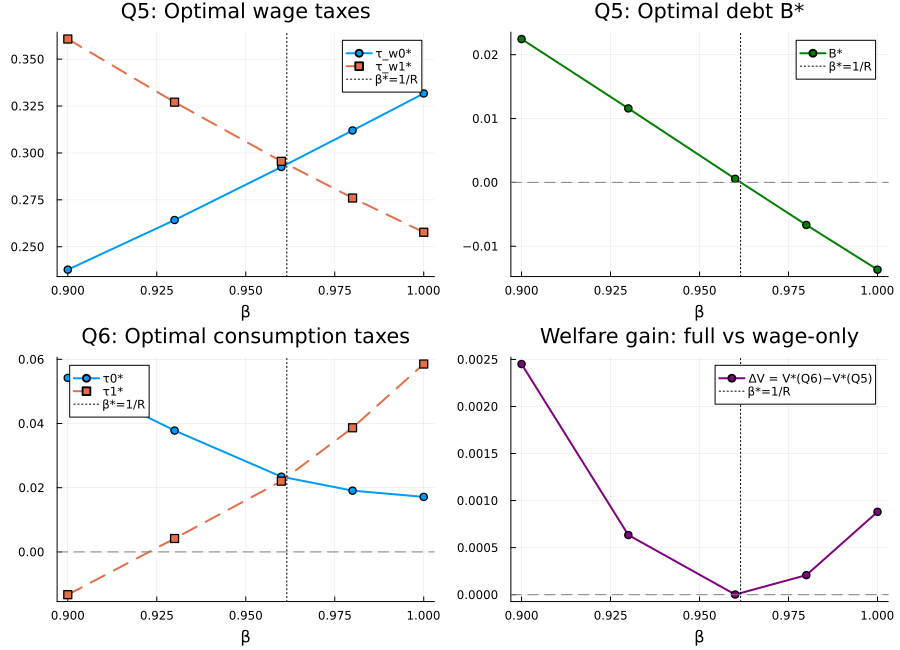

In [6]:
βs = [0.90, 0.93, 0.96, 0.98, 1.00]
q5_τw0=zeros(5); q5_τw1=zeros(5); q5_B=zeros(5); q5_V=zeros(5)
q6_τ0=zeros(5);  q6_τ1=zeros(5);  q6_V=zeros(5)
q6_τw0=zeros(5); q6_τw1=zeros(5)

@printf "%-5s  %-8s  %-8s  %-9s  %-8s  %-8s  %-10s\n" "β" "τ_w0*" "τ_w1*" "B*" "V*(Q5)" "V*(Q6)" "ΔV"

let x5=[0.35,0.35,0.0], x6=[0.0,0.0,0.35,0.35,0.0]
    for (k,β) in enumerate(βs)
        p = merge(params, (β=β,))
        r5k = run_ramp_q5(p, x5)
        r6k = run_ramp_q6(p, x6)
        q5_τw0[k]=r5k.tau_w0; q5_τw1[k]=r5k.tau_w1
        q5_B[k]=r5k.B;        q5_V[k]=r5k.V
        q6_τ0[k]=r6k.tau0;    q6_τ1[k]=r6k.tau1; q6_V[k]=r6k.V
        q6_τw0[k]=r6k.tau_w0; q6_τw1[k]=r6k.tau_w1
        @printf "%.2f   %.6f  %.6f  %+.5f  %.6f  %.6f  %+.2e\n" β r5k.tau_w0 r5k.tau_w1 r5k.B r5k.V r6k.V (r6k.V-r5k.V)
        x5=[r5k.tau_w0,r5k.tau_w1,r5k.B]
        x6=[r6k.tau0,r6k.tau1,r6k.tau_w0,r6k.tau_w1,r6k.B]
    end
end

println()
@printf "%-5s  %-9s  %-9s  %-9s  %-9s\n" "β" "τ0*(Q6)" "τ1*(Q6)" "τ_w0*(Q6)" "τ_w1*(Q6)"
for k in 1:5
    @printf "%.2f   %+.6f  %+.6f  %.6f   %.6f\n" βs[k] q6_τ0[k] q6_τ1[k] q6_τw0[k] q6_τw1[k]
end

ΔV    = q6_V .- q5_V
β_sep = 1/params.R

p1 = plot(βs, q5_τw0, label="τ_w0*", lw=2, marker=:circle,
          xlabel="β", title="Q5: Optimal wage taxes")
plot!(p1, βs, q5_τw1, label="τ_w1*", lw=2, marker=:square, ls=:dash)
vline!(p1, [β_sep], label="β*=1/R", ls=:dot, color=:black)

p2 = plot(βs, q5_B, label="B*", lw=2, marker=:circle, color=:green,
          xlabel="β", title="Q5: Optimal debt B*")
vline!(p2, [β_sep], label="β*=1/R", ls=:dot, color=:black)
hline!(p2, [0.0], ls=:dash, color=:gray, label="")

p3 = plot(βs, q6_τ0, label="τ0*", lw=2, marker=:circle,
          xlabel="β", title="Q6: Optimal consumption taxes")
plot!(p3, βs, q6_τ1, label="τ1*", lw=2, marker=:square, ls=:dash)
vline!(p3, [β_sep], label="β*=1/R", ls=:dot, color=:black)
hline!(p3, [0.0], ls=:dash, color=:gray, label="")

p4 = plot(βs, ΔV, label="ΔV = V*(Q6)−V*(Q5)", lw=2, marker=:circle, color=:purple,
          xlabel="β", title="Welfare gain: full vs wage-only")
vline!(p4, [β_sep], label="β*=1/R", ls=:dot, color=:black)
hline!(p4, [0.0], ls=:dash, color=:gray, label="")

plot(p1, p2, p3, p4, layout=(2,2), size=(900,650))

## Question 7B

**(i)**
The labor taxes are equal only when βR = 1, meaning the problem is separable. Since we treat both within-period problems as the same problem, taxes must be equal, which is exactly what we see: at β = 1/1.04 the two wage taxes are identical, and at β = 0.96 (βR = 0.998) they differ only slightly.

**(ii)**
In the labor-only case:

If β < 1/R, the consumer is impatient and taxes in period 0 are smaller than taxes in period 1. The government will also take on debt in period 0 (B > 0) and will pay it back in period 1, when the taxes are raised.

If β > 1/R, the consumer is patient and the opposite is true. The government will run a surplus in period 0 (B < 0) and tax more heavily in that period.

In the full-instrument case the taxes on consumption work in the opposite direction from the labor taxes. While they stay small, they always oppose the changes in the wage tax, so the combined wedge (1+τ_t)/(1−τ_w,t) between consumption and leisure stays about the same in both periods (about 1.42 for every β). The consumption tax path instead tilts the intertemporal price (1+τ0)/(1+τ1) that enters the Euler equation.

**(iii)**
The welfare gap grows as β moves away from 1/R and is essentially 0 at the separability point. Consumption taxes are only useful when βR is not equal to 1. At βR = 1, the two instruments are redundant and nothing changes. However, when the intertemporal margin is distorted, having two different instruments lets the government close that gap and reach a better solution than with labor taxes on their own.